# code_046 · Exploration as a recorded hypothesis process

**Book:** section 9.5. A self-contained exploration laboratory using invented building, load and sensor records. Prerequisites: arrays/tables and Chapter 8's case, timing and schema contracts. Restart and run all cells; all imports, helpers and generated inputs are here. Ordinary execution needs no files, network, keys, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_09_GUIDE.md), [execution evidence](../CHAPTER_09_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_046).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow one minute to run and 30–60 minutes to interpret. These scoped concept experiments disclose data/task controls rather than claim exhaustive estimator API coverage. Plots and construction identities are exploratory diagnostics, not independent predictive evidence. Only the hypothesis laboratory fits competing predictors, selects on development buildings and opens a protected final set after freezing its rule. All evidence is synthetic, with no structural-safety, population-calibration or causal claim.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=946;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 946


<a id="contract"></a>
## Record an exploratory pattern before converting it into a final claim

Generate 120 independent buildings, each with four readings. Normalized temperature T=(temperature_C-20)/10 is uniform [-1,1] and normalized load L=(load_kN-10)/10 uniform [0,1]. Target y=.3+.1*T+.4*L+.5*T*L+building_offset+noise mm, with building offsets sd .2 and reading noise sd .1. The generator deliberately contains an interaction. Split whole buildings before analysis: 72 train,24 develop,24 final. All input measurements are available at prediction; building offsets are latent, not exposed as features. Units and reference scaling are fixed physical conventions, not fitted using final inputs.

Eligible predictors are ordinary least-squares linear [1,T,L] and interaction [1,T,L,T*L]. Fit on training only. Development equal-building MSE selects the procedure with a deterministic first-candidate tie rule. No best random seed, hidden extra candidates or final refit. Predeclare the final question: report paired linear-minus-selected building MSE and whether its mean exceeds an illustrative .005 mm² practical threshold; no structural-safety meaning is attached.


In [2]:
G=120;m=4;building=np.repeat(np.arange(G),m);T=rng.uniform(-1,1,G*m);L=rng.uniform(0,1,G*m);offset=rng.normal(0,.2,G)
y=.3+.1*T+.4*L+.5*T*L+offset[building]+rng.normal(0,.1,G*m)
tr=building<72;dv=(building>=72)&(building<96);te=building>=96
assert not set(building[tr])&set(building[dv]) and not set(building[tr])&set(building[te]) and not set(building[dv])&set(building[te])
X0=np.column_stack([np.ones(len(T)),T,L]);X1=np.column_stack([X0,T*L]);features={'linear':X0,'interaction':X1};fitted={k:np.linalg.lstsq(X[tr],y[tr],rcond=None)[0] for k,X in features.items()}
assert np.linalg.matrix_rank(X0[tr])==3 and np.linalg.matrix_rank(X1[tr])==4
assert np.allclose(X0[tr].T@(y[tr]-X0[tr]@fitted['linear']),0,atol=1e-10)
RESULTS['role_building_counts']={'train':72,'development':24,'final':24}


<a id="ledger"></a>
## Describe competing explanations, then freeze a check

On development buildings the linear residual appears related to T*L. Candidate explanations: a genuine non-additive response under this simulator; a sensor offset correlated with operating regime; different buildings occupying different temperature/load ranges; or chance. The plot cannot choose a causal explanation. The extra product feature is a predictive check, not a claim that intervening on temperature has that fitted effect. Record where the pattern was seen, which units were inspected and what would count against the proposed check. Development remains adaptive evidence even after the ledger is written.


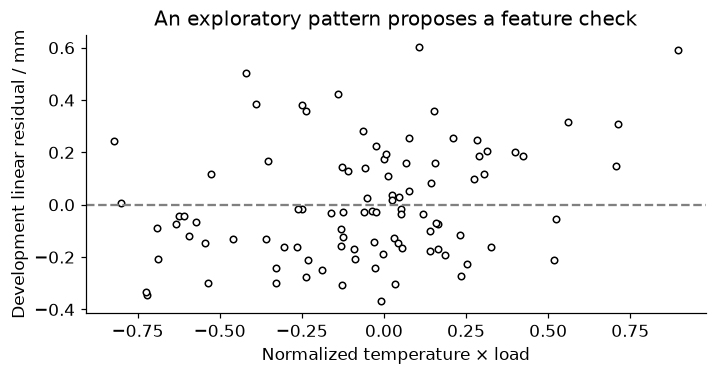

In [3]:
residual=y[dv]-X0[dv]@fitted['linear'];fig,ax=plt.subplots(figsize=(6.4,3.3));ax.scatter((T*L)[dv],residual,s=18,facecolors='white',edgecolors='black');ax.axhline(0,color='.5',ls='--');ax.set(xlabel='Normalized temperature × load',ylabel='Development linear residual / mm',title='An exploratory pattern proposes a feature check');plt.show()
ledger={'observed_on':'24 development buildings only','pattern':'linear residual varies with temperature-load product','alternatives':['non-additive response','regime-linked sensor offset','building mix','chance'],'eligible_predictors':['linear','interaction'],'fit_cases':'72 training buildings','selection_metric':'equal-building development MSE mm²','practical_final_gain_mm2':.005,'final_policy':'one paired assessment; no winner-based redesign','limits':['synthetic interaction favors candidate','development was used to propose and select','no causal coefficient claim']}
assert ledger['observed_on']=='24 development buildings only' and ledger['final_policy'].startswith('one paired')
development={k:float(np.mean((features[k][dv]@fitted[k]-y[dv])**2)) for k in features};selected=min(development,key=development.get)
assert selected in ledger['eligible_predictors'];frozen_coefficients={k:v.copy() for k,v in fitted.items()}
RESULTS['development_MSE_mm2']=development;RESULTS['selected_procedure']=selected;RESULTS['hypothesis_ledger']=ledger


<a id="final"></a>
## Open final buildings once under the frozen rule

Compute each building's mean squared error, then pair the same buildings for the baseline and selected procedure. Equal reading counts make the aggregate equal the row average here, but the unit is still the building. A fixed 2,000-replicate paired building bootstrap gives a descriptive percentile interval conditional on the frozen procedures and these assumptions, not a guarantee of coverage or correction for all exploration. The plot retains every final building's gain; negative values expose losses. Subsequent redesign needs a fresh final cohort.


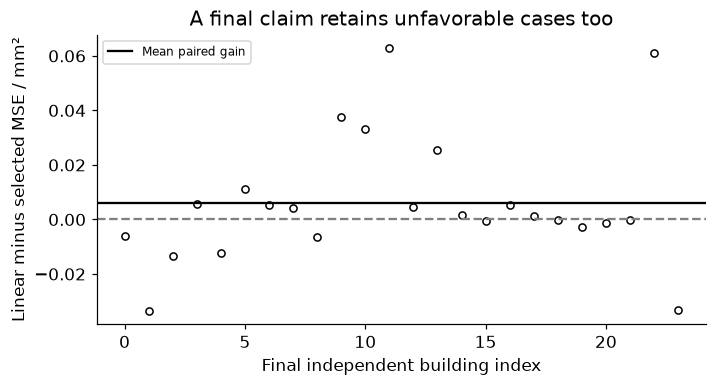

In [4]:
errors={k:((features[k][te]@fitted[k]-y[te])**2).reshape(24,m).mean(1) for k in features}
gain=errors['linear']-errors[selected];boot_rng=np.random.default_rng(SEED+10000);bootstrap=gain[boot_rng.integers(0,24,size=(2000,24))].mean(1);interval=np.quantile(bootstrap,[.025,.975])
assert gain.shape==(24,) and np.isclose(gain.mean(),errors['linear'].mean()-errors[selected].mean())
assert all(np.array_equal(fitted[k],frozen_coefficients[k]) for k in fitted)
fig,ax=plt.subplots(figsize=(6.4,3.4));ax.scatter(np.arange(24),gain,s=22,facecolors='white',edgecolors='black');ax.axhline(0,color='.5',ls='--');ax.axhline(gain.mean(),color='black',label='Mean paired gain');ax.set(xlabel='Final independent building index',ylabel='Linear minus selected MSE / mm²',title='A final claim retains unfavorable cases too');ax.legend(fontsize=8);plt.show()
RESULTS['final_MSE_mm2']={k:float(v.mean()) for k,v in errors.items()};RESULTS['paired_mean_gain_mm2']=float(gain.mean());RESULTS['paired_2000_bootstrap_percentile_95_mm2']=interval.tolist();RESULTS['illustrative_practical_threshold_met']=bool(gain.mean()>=.005);RESULTS['final_buildings_with_negative_gain']=int((gain<0).sum())


<a id="exercises"></a>
## Exercises and hints

1. Remove the interaction from the generator in a new study. Retain a null/negative result rather than change seeds for a favorable story.
2. Add ten candidate features and record every attempt; explain why development performance becomes more adaptive.
3. Use a new independent cohort after changing the model in response to final errors.
4. Distinguish exploratory evidence, a prespecified metric/check and an intervention claim about temperature.

**Hints:** a timestamped ledger improves traceability but cannot turn previously inspected outcomes into untouched evidence. This small comparison tests the declared predictors and generator, not all feature engineering. The primary discussion of [model-selection bias](https://www.jmlr.org/papers/v11/cawley10a.html) motivates separate evaluation; it is not an empirical benchmark for this toy example.


In [5]:
summary={'example_id':'code_046','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['exploration ledger and alternative explanations', 'temperature-load interaction discovered on development', 'training-only fit and group-disjoint roles', 'frozen candidate selection and one final assessment', 'paired building uncertainty and limits'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["exploration ledger and alternative explanations", "temperature-load interaction discovered on development", "training-only fit and group-disjoint roles", "frozen candidate selection and one final assessment", "paired building uncertainty and limits"], "elapsed_seconds": 0.134, "example_id": "code_046", "hardware": "Darwin arm64 CPU", "results": {"development_MSE_mm2": {"interaction": 0.04348849200219349, "linear": 0.04684484915338121}, "final_MSE_mm2": {"interaction": 0.052811375210892166, "linear": 0.05899337765783036}, "final_buildings_with_negative_gain": 11, "hypothesis_ledger": {"alternatives": ["non-additive response", "regime-linked sensor offset", "building mix", "chance"], "eligible_predictors": ["linear", "interaction"], "final_policy": "one paired assessment; no winner-based redesign", "fit_cases": "72 training buildings", "limits": ["synthetic interaction favors candidate", "development was used to propose and select", "no 